# Path 1, P2a — log timing and off-grid values (Oct 25, 2026)

Data: `load_runs("behavior")`: train groups only (split G), Full, Hierarchy, Star; aborted 1-row rounds and whole-second files dropped. Gap = time between consecutive log rows. n_movers = human players whose k = round(10 s) changed in that row. Functions: `src/slider/logtiming.py`. Nothing is saved.

In [1]:
from slider import slider_logs as sl
from slider import logtiming as lt

runs, table = sl.load_runs("behavior")
gaps = lt.row_gaps(runs)
og = lt.off_grid(runs)
gaps.groupby("dataset").size().loc[lt.DATASETS]     # gaps per dataset

dataset
EL     9082
CL    29942
CC    97110
dtype: int64

## a) Gap quantiles (s)

In [2]:
lt.gap_quantiles(gaps)

,min,1%,5%,25%,50%,75%,95%,99%
dataset,,,,,,,,
EL,0.05,0.050,0.050,0.100,0.100,0.200,0.500,1.400
CL,0.05,0.050,0.050,0.100,0.100,0.110,0.500,1.100
CC,0.00,0.001,0.001,0.007,0.024,0.042,0.329,0.889


## b) Gaps in [0, 1] s, bins of 0.005 s

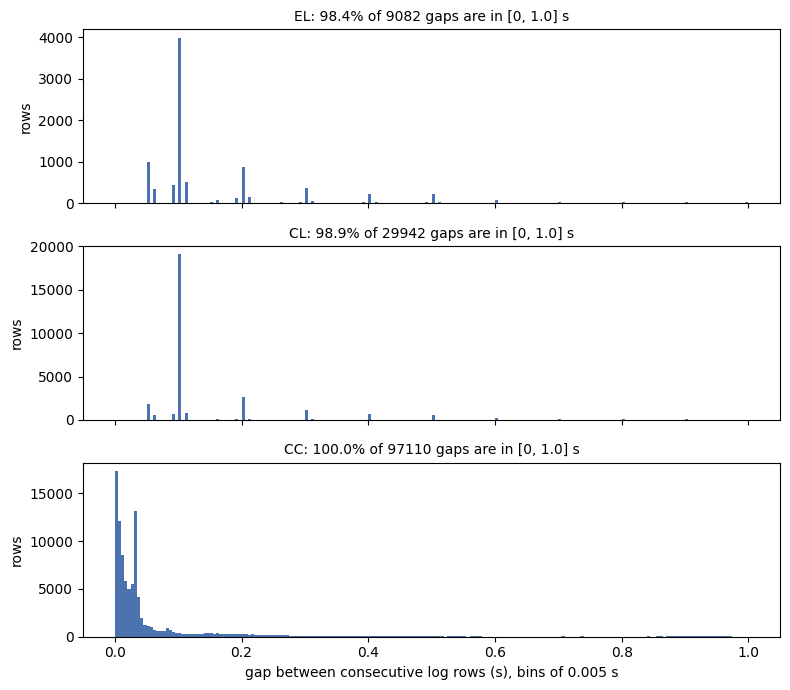

In [3]:
lt.plot_gap_hist(gaps)

## c) The 10 most common gaps (rounded to 1 ms), and the timestamp resolution

Resolution: number of logged times with 0, 1, 2, … decimals; the largest row with a nonzero count is the resolution. Cloud times are clock time minus the clock at the start of the round, so they keep the clock's decimals.

In [4]:
lt.top_values(gaps, "gap", n=10, decimals=3)

EL          CL            CC      
     gap     n   gap      n    gap     n
1   0.10  3990  0.10  19070  0.001  5412
2   0.05  1004  0.20   2672  0.002  4580
3   0.20   879  0.05   1864  0.033  4084
4   0.11   517  0.30   1166  0.003  3375
5   0.09   438  0.11    757  0.004  3081
6   0.30   370  0.40    688  0.032  2865
7   0.06   332  0.09    659  0.005  2861
8   0.40   229  0.06    629  0.006  2678
9   0.50   226  0.50    548  0.034  2541
10  0.21   160  0.60    250  0.007  2394

In [5]:
lt.time_decimals(runs)

dataset,EL,CL,CC
decimals,,,
0,80,444,231
1,724,3766,908
2,8311,25798,8870
3,0,0,87246


## d) Lab only: median gap, 1 mover vs. 2 or more

In [6]:
lt.lab_gap_by_movers(gaps)

rows  median_gap
dataset movers                   
EL      1        6593         0.1
        >= 2     2489         0.1
CL      1       16007         0.1
        >= 2     7455         0.1

## e) Values off the 0.1 grid (|10 s − round(10 s)| > 1e-6)

Share by dataset and seat type, the 10 most common off-grid values, and the share in the first row, the last row and the rows in between.

In [7]:
lt.off_grid_share(og).round(2)

values  off_grid    pct
dataset seat_type                         
EL      human       63805         0   0.00
CL      human      210056     31002  14.76
CC      bot         24566         0   0.00
        human      656219         0   0.00

In [8]:
lt.top_values(og[og["off_grid"]], "value", n=10, decimals=6)

EL        CL          CC    
   value   n value     n value   n
1    NaN NaN  0.98  1156   NaN NaN
2    NaN NaN -0.98  1027   NaN NaN
3    NaN NaN  0.02  1011   NaN NaN
4    NaN NaN  0.72   672   NaN NaN
5    NaN NaN -0.02   666   NaN NaN
6    NaN NaN  0.88   619   NaN NaN
7    NaN NaN  0.96   587   NaN NaN
8    NaN NaN -0.46   575   NaN NaN
9    NaN NaN  0.04   559   NaN NaN
10   NaN NaN  0.78   526   NaN NaN

In [9]:
lt.off_grid_position(og).round(2)

values  off_grid    pct
dataset position                         
EL      first        231         0   0.00
        last         231         0   0.00
        middle     63343         0   0.00
CL      first        462         8   1.73
        last         462        14   3.03
        middle    209132     30980  14.81
CC      first       1015         0   0.00
        last        1015         0   0.00
        middle    678755         0   0.00